# Prepare the Tabula Sapiens dataset

Download or extract the source H5AD if needed, select a reproducible sample, filter cells and genes, and select highly variable genes by excess variance over a smooth mean–variance trend. The notebook preserves raw counts and full-gene log-expression in an H5AD file, saves ranked and selected HVG outputs, and builds the PCA feature cache used by the embedding notebook.


In [1]:
%load_ext autoreload
%autoreload 2

%config InlineBackend.figure_format = 'retina'

from pathlib import Path
import json
import sys
import shutil
import zipfile
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "imste" / "__init__.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate the IMSTE repository from the notebook working directory.")
for local_path in (PROJECT_ROOT, PROJECT_ROOT / "notebooks" / "src"):
    local_path = str(local_path)
    if local_path in sys.path:
        sys.path.remove(local_path)
    sys.path.insert(0, local_path)
import imste
if not Path(imste.__file__).resolve().is_relative_to(PROJECT_ROOT.resolve()):
    raise RuntimeError("This kernel loaded IMSTE from another location; restart and run from the top.")
from imste import IteratedMinimumSpanningTreeEmbedder
from single_cell_preprocessing import (
    preprocess_count_data,
    sample_indices_by_group,
    scale_and_pca,
    select_hvgs_excess_variance,
)

DATA_DIR = PROJECT_ROOT / "data" / "tabula_sapiens"
DATA_DIR.mkdir(parents=True, exist_ok=True)
ARCHIVE_PATH = DATA_DIR / "TabulaSapiens_v1.h5ad.zip"
H5AD_PATH = DATA_DIR / "TabulaSapiens.h5ad"
if not H5AD_PATH.is_file():
    if not ARCHIVE_PATH.is_file():
        raise FileNotFoundError(f"Expected the dataset archive at {ARCHIVE_PATH}.")
    try:
        with zipfile.ZipFile(ARCHIVE_PATH) as archive:
            h5ad_members = [name for name in archive.namelist() if name.lower().endswith(".h5ad")]
            if len(h5ad_members) != 1:
                raise RuntimeError(f"Expected one H5AD file in {ARCHIVE_PATH.name}; found {h5ad_members}.")
            member = archive.getinfo(h5ad_members[0])
            required_bytes = member.file_size + 1_000_000_000
            if shutil.disk_usage(DATA_DIR).free < required_bytes:
                raise OSError(
                    f"Not enough free space to extract {member.file_size / 1e9:.1f} GB; "
                    f"need at least {required_bytes / 1e9:.1f} GB free."
                )
            print(f"Extracting {member.filename} ({member.file_size / 1e9:.1f} GB)...")
            with archive.open(member) as source, H5AD_PATH.open("wb") as destination:
                shutil.copyfileobj(source, destination, length=16 * 1024 * 1024)
    except zipfile.BadZipFile as error:
        raise RuntimeError(
            "The Tabula Sapiens ZIP is incomplete or invalid. Wait for the download to finish, then rerun this cell."
        ) from error
    print(f"Extracted dataset to {H5AD_PATH}; the source ZIP is retained.")

In [5]:
RANDOM_STATE = 42
MAX_CELLS_PER_CLASS = 1_000  # Set to None to use every cell.
MIN_CELLS_PER_CELL_TYPE = 2_000  # Exclude cell types with fewer source cells; set to None to disable.
SAMPLE_BY = "cell_type"  # "cell_type" or "tissue"; both rows use this same sample.
TARGET_SUM = 10_000
MIN_GENES_PER_CELL = 200  # Set to None to disable the cell-quality threshold.
MIN_CELLS_PER_GENE = 3  # Set to None to disable this threshold; never-detected genes are always removed.
N_HVG = 2_000
BATCH_AWARE_HVG = True  # Set False or BATCH_COLUMN=None for one global ranking.
BATCH_COLUMN = "donor"  # Tabula Sapiens donor labels; change to another obs column as needed.
N_PCS = 300
METRIC = 'euclidean'

## Load annotations and cap cells per class

The source object is opened in backed mode so the full expression matrix is not loaded just to inspect labels. Cell types below `MIN_CELLS_PER_CELL_TYPE` source cells are filtered out first. Then we sample up to `MAX_CELLS_PER_CLASS` cells within each class of `SAMPLE_BY`; setting either threshold to `None` disables that filter. A fixed random seed makes the selected cells reproducible. Expression-based cell and gene QC is applied to the sampled raw-count matrix before normalization.


Source: 483,152 cells × 58,870 genes
Cell-type filter: kept 54/177 types with at least 2000 cells; selected 54,000 of 483,152 source cells.
Sample cap: 1000 cells per cell_type class.
Tissue annotation: organ_tissue; cell-type annotation: cell_ontology_class


,organ_tissue,cell_ontology_class,cells
0,Bladder,b cell,14
1,Bladder,bladder urothelial cell,1000
2,Bladder,capillary endothelial cell,17
3,Bladder,fibroblast,175
4,Bladder,macrophage,153
5,Bladder,mast cell,450
6,Bladder,myofibroblast cell,658
7,Bladder,nk cell,57
8,Bladder,pericyte cell,197
9,Bladder,plasma cell,99


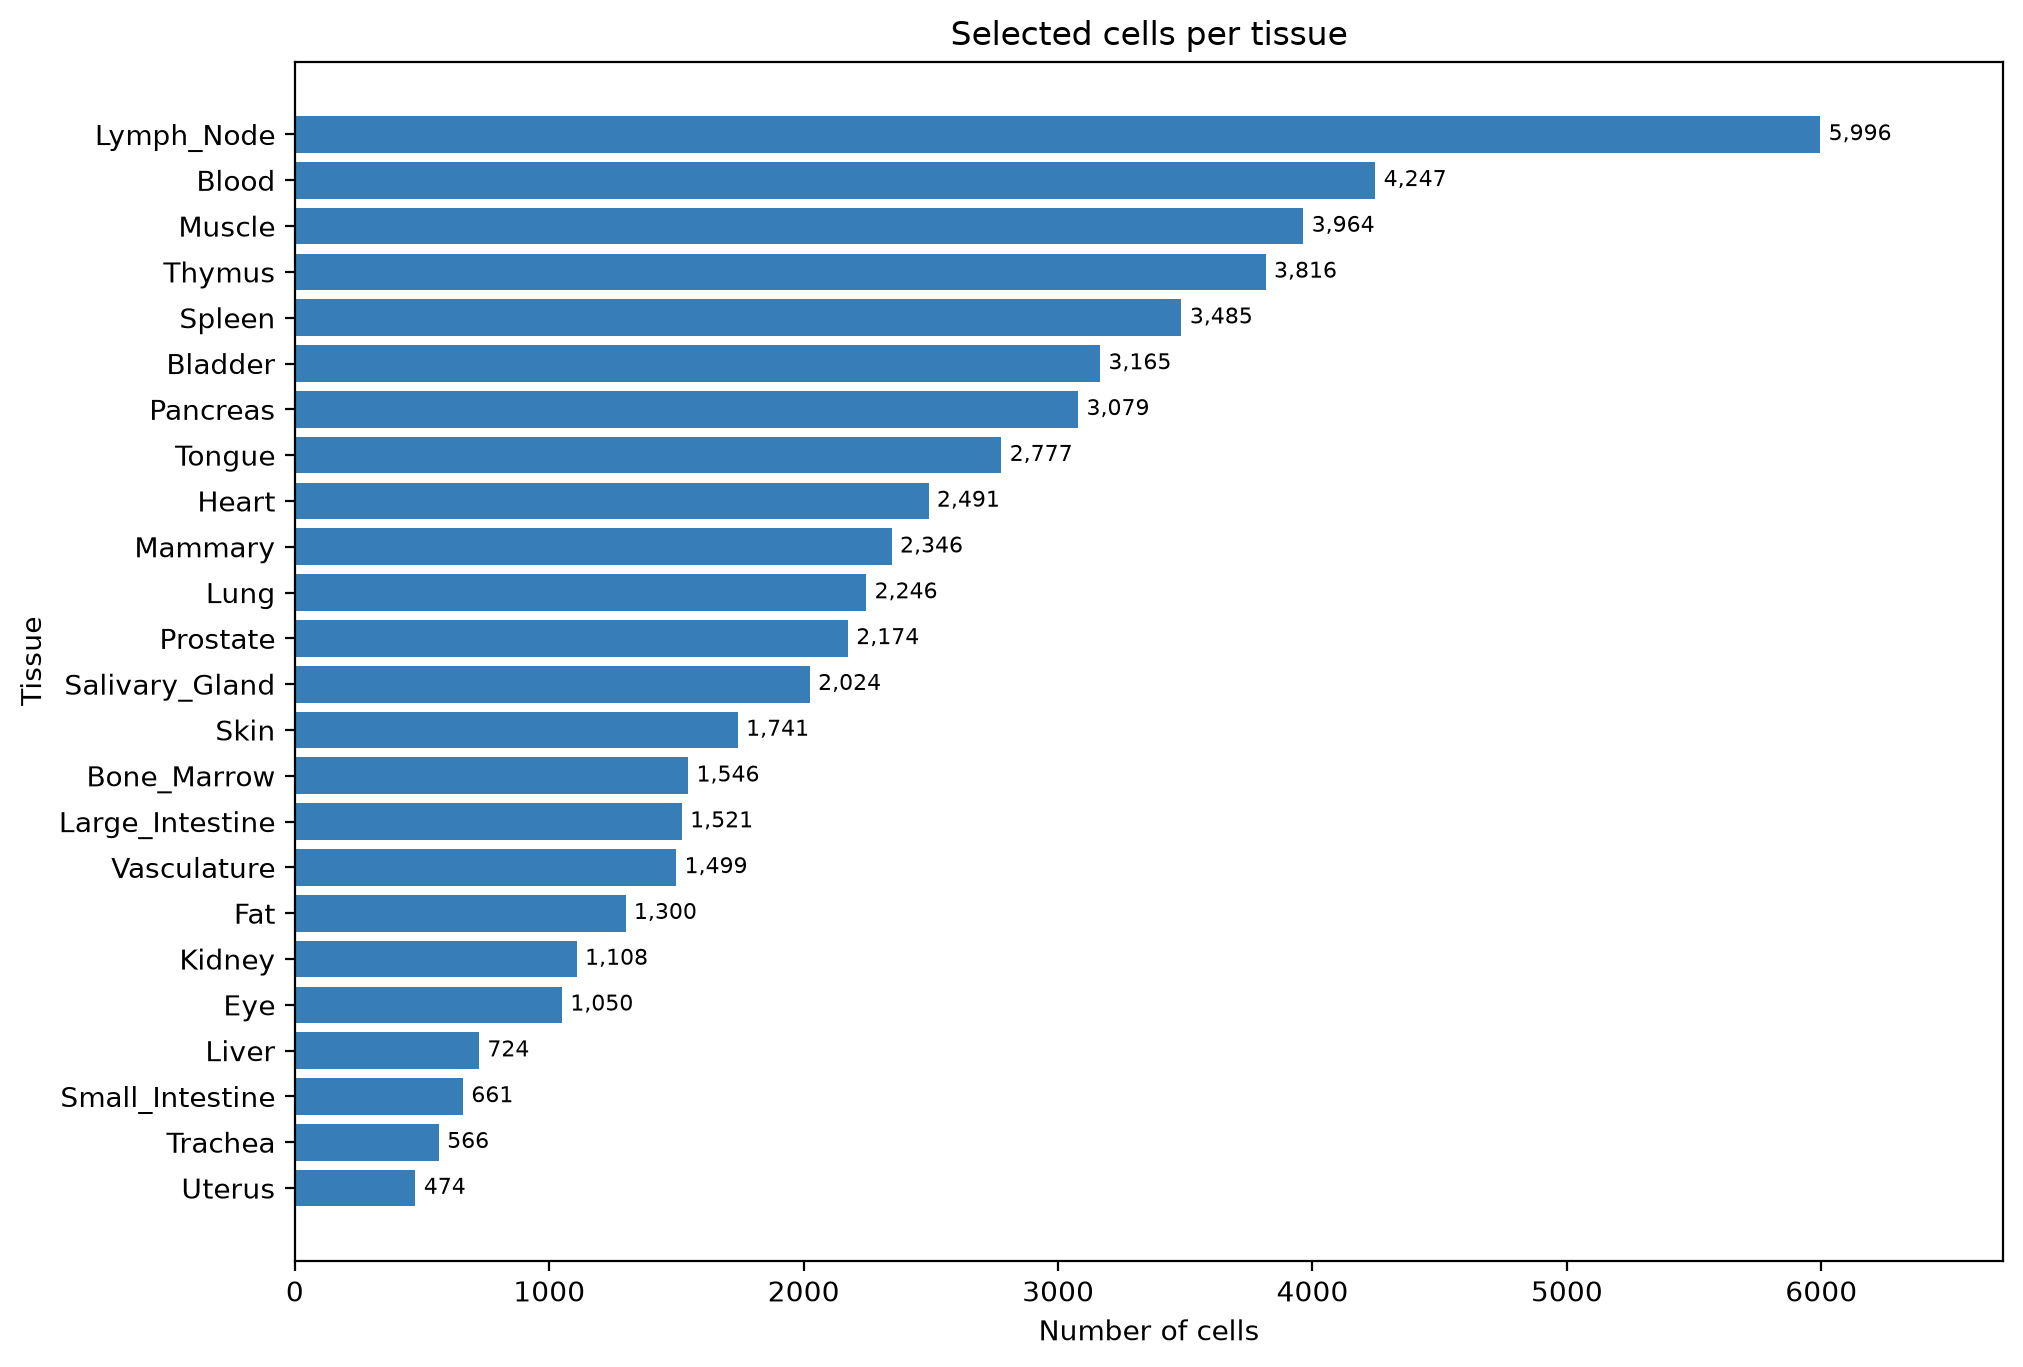

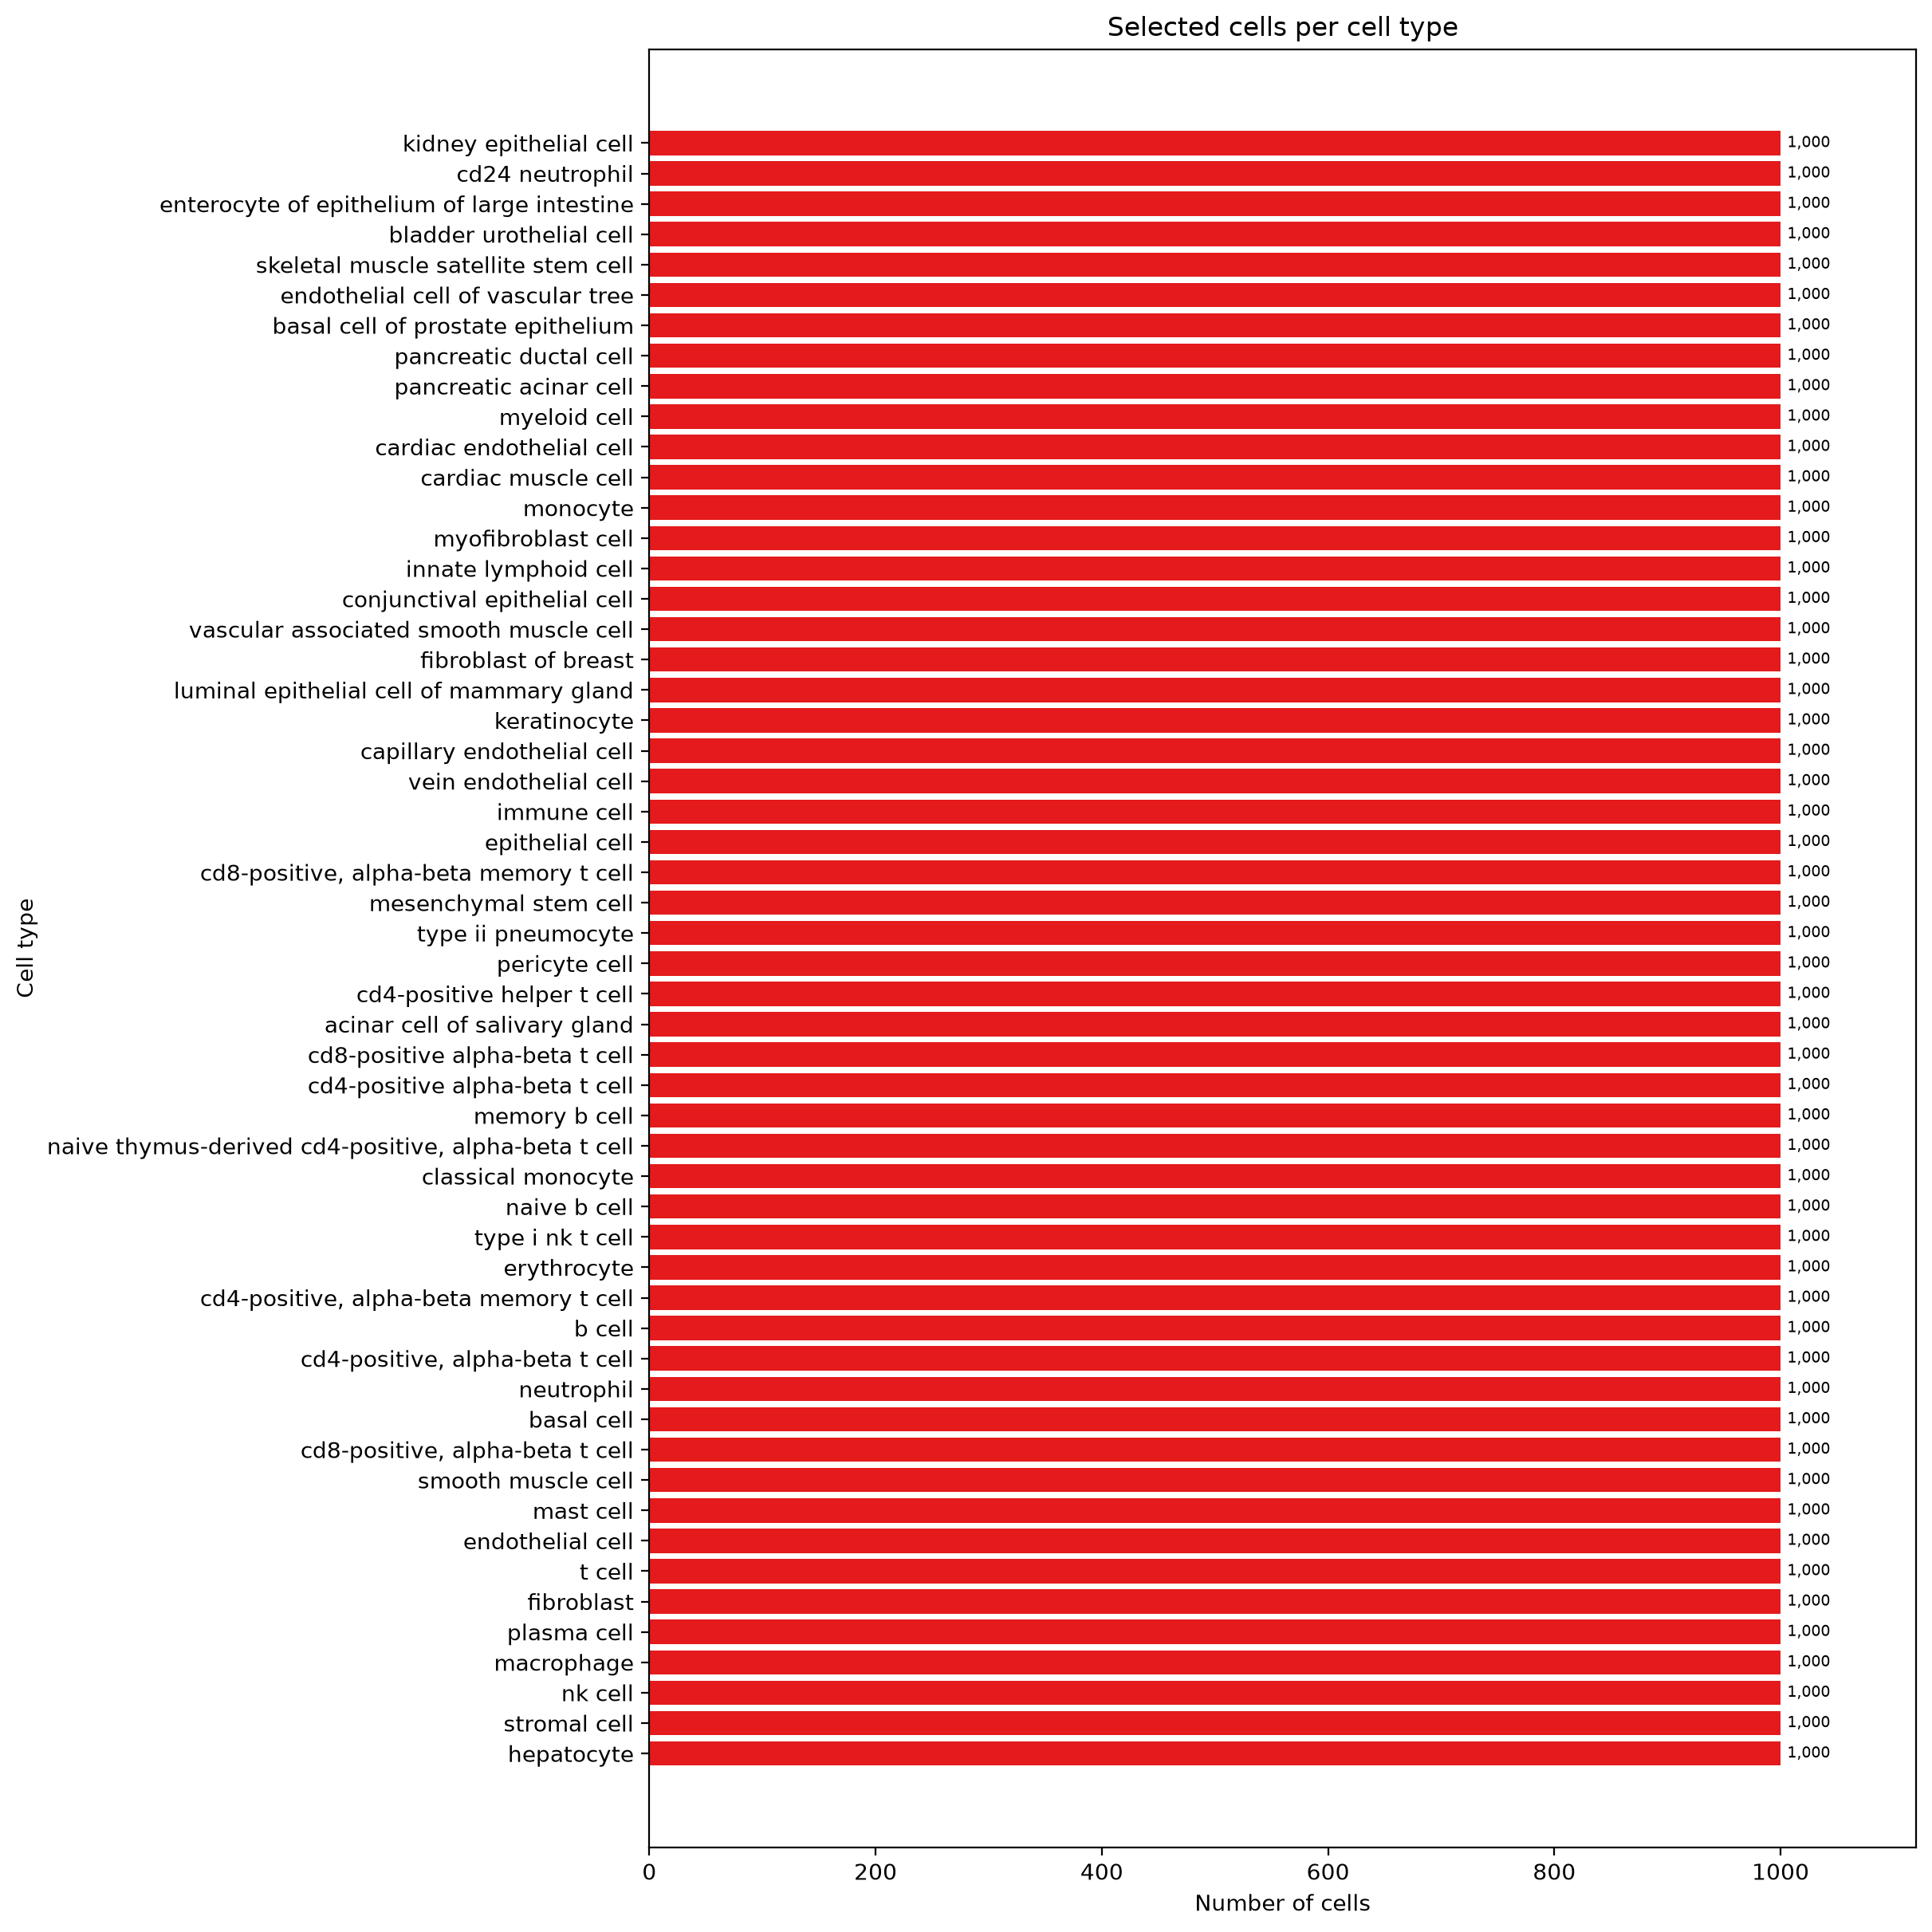

In [6]:
adata_source = sc.read_h5ad(H5AD_PATH, backed="r")

# Tabula Sapiens v1 annotation names; prefer the atlas' ontology cell types.
def first_available(columns, candidates, description):
    for name in candidates:
        if name in columns:
            return name
    raise KeyError(f"Could not find {description}; available obs columns: {list(columns)}")

tissue_column = first_available(
    adata_source.obs.columns, ("organ_tissue", "tissue", "tissue_general"), "tissue annotation"
)
cell_type_column = first_available(
    adata_source.obs.columns, ("cell_ontology_class", "cell_type", "free_annotation"), "cell-type annotation"
)
if SAMPLE_BY not in {"cell_type", "tissue"}:
    raise ValueError("SAMPLE_BY must be 'cell_type' or 'tissue'.")
sampling_column = cell_type_column if SAMPLE_BY == "cell_type" else tissue_column

metadata_columns = [tissue_column, cell_type_column]
if BATCH_AWARE_HVG and BATCH_COLUMN is not None:
    if BATCH_COLUMN not in adata_source.obs.columns:
        raise KeyError(f"Batch column {BATCH_COLUMN!r} is missing; available obs columns: {list(adata_source.obs.columns)}")
    if BATCH_COLUMN not in metadata_columns:
        metadata_columns.append(BATCH_COLUMN)
obs = adata_source.obs[metadata_columns].copy()
obs[tissue_column] = obs[tissue_column].astype("string").fillna("unannotated").astype(str)
obs[cell_type_column] = obs[cell_type_column].astype("string").fillna("unannotated").astype(str)
if BATCH_AWARE_HVG and BATCH_COLUMN is not None:
    obs[BATCH_COLUMN] = obs[BATCH_COLUMN].astype("string").fillna("unknown_batch").astype(str)
cell_type_source_counts = obs[cell_type_column].value_counts()
if MIN_CELLS_PER_CELL_TYPE is not None:
    if not isinstance(MIN_CELLS_PER_CELL_TYPE, int) or MIN_CELLS_PER_CELL_TYPE < 1:
        raise ValueError("MIN_CELLS_PER_CELL_TYPE must be a positive integer or None.")
    retained_types = cell_type_source_counts[
        cell_type_source_counts >= MIN_CELLS_PER_CELL_TYPE
    ].index
else:
    retained_types = cell_type_source_counts.index

eligible_mask = obs[cell_type_column].isin(retained_types).to_numpy()
selected_indices = sample_indices_by_group(
    obs[sampling_column].to_numpy(),
    eligible_mask=eligible_mask,
    max_per_group=MAX_CELLS_PER_CLASS,
    random_state=RANDOM_STATE,
)

print(f"Source: {adata_source.n_obs:,} cells × {adata_source.n_vars:,} genes")
print(
    f"Cell-type filter: kept {len(retained_types):,}/{len(cell_type_source_counts):,} types "
    f"with at least {MIN_CELLS_PER_CELL_TYPE if MIN_CELLS_PER_CELL_TYPE is not None else 'any'} cells; "
    f"selected {len(selected_indices):,} of {adata_source.n_obs:,} source cells."
)
print(f"Sample cap: {MAX_CELLS_PER_CLASS} cells per {SAMPLE_BY} class.")
print(f"Tissue annotation: {tissue_column}; cell-type annotation: {cell_type_column}")
display(obs.iloc[selected_indices].groupby([tissue_column, cell_type_column], observed=True).size()
        .rename("cells").reset_index().head(20))

selected_obs = obs.iloc[selected_indices]
tissue_counts = selected_obs[tissue_column].value_counts().sort_values()
cell_type_counts = selected_obs[cell_type_column].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, max(5, 0.28 * len(tissue_counts))), constrained_layout=True)
bars = ax.barh(tissue_counts.index, tissue_counts.values, color="#377eb8")
ax.bar_label(bars, fmt="{:,.0f}", padding=3, fontsize=8)
ax.set_xlim(0, tissue_counts.max() * 1.12)
ax.set_title("Selected cells per tissue")
ax.set_xlabel("Number of cells")
ax.set_ylabel("Tissue")
plt.show()

fig, ax = plt.subplots(figsize=(12, max(12, 0.17 * len(cell_type_counts))), constrained_layout=True)
bars = ax.barh(cell_type_counts.index, cell_type_counts.values, color="#e41a1c")
ax.bar_label(bars, fmt="{:,.0f}", padding=3, fontsize=7)
ax.set_xlim(0, cell_type_counts.max() * 1.12)
ax.set_title("Selected cells per cell type")
ax.set_xlabel("Number of cells")
ax.set_ylabel("Cell type")
plt.show()

## Filter, normalize, rank genes, and compute PCA

Cell and gene filters are applied to the sampled raw-count matrix. The retained raw counts are kept in `layers["raw_counts"]`; `X` becomes normalized `log1p` expression and retains every filtered-in gene. A smooth spline trend in log mean/log variance supplies the expected variance. The full ranked table is ordered by global excess-variance score. When batch-aware mode is enabled, per-batch top-N sets are combined by selecting genes found in the most batches, then breaking ties by mean within-batch excess variance, global excess variance, and gene name. The table also records each gene’s selection rank and number of selecting batches. PCA is computed from a selected-gene copy, leaving the full expression matrix available in memory and in the saved H5AD.


In [7]:
# Preserve source row indices through quality filtering so the PCA cache stays aligned.
if "raw_counts" not in adata_source.layers:
    raise KeyError(f"Expected layers['raw_counts']; available layers: {list(adata_source.layers.keys())}")

adata_sample = adata_source[selected_indices].to_memory()
adata_source.file.close()
adata = sc.AnnData(
    X=adata_sample.layers["raw_counts"].copy(),
    obs=obs.iloc[selected_indices].copy(),
    var=adata_sample.var.copy(),
)
del adata_sample
adata.obs["_source_index"] = selected_indices

adata = preprocess_count_data(
    adata,
    target_sum=TARGET_SUM,
    min_genes_per_cell=MIN_GENES_PER_CELL,
    min_cells_per_gene=MIN_CELLS_PER_GENE,
)
selected_indices = adata.obs.pop("_source_index").to_numpy(dtype=np.int64)
selection = select_hvgs_excess_variance(
    adata,
    n_top_genes=N_HVG,
    batch_key=BATCH_COLUMN,
    batch_aware=BATCH_AWARE_HVG,
)
ranked_genes = selection.ranked_genes
selected_gene_names = selection.selected_gene_names
selection_mask = selection.selection_mask
selection_method = selection.method
n_selected = len(selected_gene_names)
n_batches = selection.n_batches

# Keep full-gene expression in adata; use an HVG-only copy for PCA.
adata_hvg = adata[:, selection_mask].copy()
X = scale_and_pca(
    adata_hvg,
    n_pcs=N_PCS,
    random_state=RANDOM_STATE,
    zero_center=False,
    max_value=10,
)
tissue_labels = adata.obs[tissue_column].astype(str).to_numpy()
cell_type_labels = adata.obs[cell_type_column].astype(str).to_numpy()
print(
    f"Filtered expression: {adata.n_obs:,} cells × {adata.n_vars:,} genes; "
    f"selected {n_selected:,} HVGs by {selection_method}."
)
print(f"Feature matrix: {X.shape[0]:,} cells × {X.shape[1]} PCs")
display(pd.DataFrame({"cells": [len(X)], "genes": [adata.n_vars], "HVGs": [n_selected],
                     "batches": [n_batches], "tissues": [pd.Series(tissue_labels).nunique()],
                     "cell types": [pd.Series(cell_type_labels).nunique()]}))
display(ranked_genes.head(10))

# Save the PCA handoff plus full expression and gene-selection artifacts.
CACHE_DIR = DATA_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
PREPARED_CACHE = CACHE_DIR / "tabula_sapiens_pca_sample.npz"
PREPARED_MANIFEST = CACHE_DIR / "tabula_sapiens_pca_sample_manifest.json"
TEMP_CACHE = CACHE_DIR / "tabula_sapiens_pca_sample.tmp.npz"
TEMP_MANIFEST = CACHE_DIR / "tabula_sapiens_pca_sample_manifest.tmp.json"
EXPRESSION_CACHE = CACHE_DIR / "tabula_sapiens_expression.h5ad"
TEMP_EXPRESSION = CACHE_DIR / "tabula_sapiens_expression.tmp.h5ad"
RANKED_CACHE = CACHE_DIR / "tabula_sapiens_hvg_ranked.csv"
TEMP_RANKED = CACHE_DIR / "tabula_sapiens_hvg_ranked.tmp.csv"
SELECTED_GENES_CACHE = CACHE_DIR / "tabula_sapiens_hvg_selected.txt"
TEMP_SELECTED_GENES = CACHE_DIR / "tabula_sapiens_hvg_selected.tmp.txt"
np.savez_compressed(
    TEMP_CACHE,
    X=X,
    tissue_labels=np.asarray(tissue_labels, dtype=str),
    cell_type_labels=np.asarray(cell_type_labels, dtype=str),
    selected_indices=np.asarray(selected_indices, dtype=np.int64),
    hvg_names=np.asarray(selected_gene_names, dtype=str),
)
TEMP_CACHE.replace(PREPARED_CACHE)
ranked_genes.to_csv(TEMP_RANKED, index=False)
TEMP_RANKED.replace(RANKED_CACHE)
TEMP_SELECTED_GENES.write_text("\n".join(selected_gene_names) + "\n")
TEMP_SELECTED_GENES.replace(SELECTED_GENES_CACHE)
adata.write_h5ad(TEMP_EXPRESSION, compression="gzip")
TEMP_EXPRESSION.replace(EXPRESSION_CACHE)
manifest = {
    "dataset": "Tabula Sapiens v1",
    "source_file": "data/tabula_sapiens/TabulaSapiens.h5ad",
    "random_state": RANDOM_STATE,
    "sample_by": SAMPLE_BY,
    "max_cells_per_class": MAX_CELLS_PER_CLASS,
    "min_cells_per_cell_type": MIN_CELLS_PER_CELL_TYPE,
    "min_genes_per_cell": MIN_GENES_PER_CELL,
    "min_cells_per_gene": MIN_CELLS_PER_GENE,
    "target_sum": TARGET_SUM,
    "n_hvg_requested": N_HVG,
    "n_hvg_used": int(n_selected),
    "hvg_method": "excess_variance_over_spline_trend",
    "selection_method": selection_method,
    "batch_combination": (
        "rank genes by number of batches in per-batch top-N; break ties by mean within-batch "
        "excess variance, then global excess variance, then gene name"
        if selection_method == "batch_consensus" else "global excess-variance ranking"
    ),
    "batch_aware_hvg": bool(BATCH_AWARE_HVG and BATCH_COLUMN is not None),
    "batch_column": BATCH_COLUMN if BATCH_AWARE_HVG else None,
    "n_batches": int(n_batches),
    "n_pcs_requested": N_PCS,
    "n_pcs_used": int(X.shape[1]),
    "tissue_column": tissue_column,
    "cell_type_column": cell_type_column,
    "n_cells": int(X.shape[0]),
    "n_genes": int(adata.n_vars),
    "n_tissues": int(pd.Series(tissue_labels).nunique()),
    "n_cell_types": int(pd.Series(cell_type_labels).nunique()),
    "feature_shape": [int(value) for value in X.shape],
    "expression_file": str(EXPRESSION_CACHE.relative_to(PROJECT_ROOT)),
    "ranked_genes_file": str(RANKED_CACHE.relative_to(PROJECT_ROOT)),
    "selected_genes_file": str(SELECTED_GENES_CACHE.relative_to(PROJECT_ROOT)),
}
TEMP_MANIFEST.write_text(json.dumps(manifest, indent=2) + "\n")
TEMP_MANIFEST.replace(PREPARED_MANIFEST)
print(f"Saved PCA features: {PREPARED_CACHE}")
print(f"Saved full expression: {EXPRESSION_CACHE}")
print(f"Saved ranked genes: {RANKED_CACHE}")
print(f"Saved selected genes: {SELECTED_GENES_CACHE}")
print(f"Saved manifest: {PREPARED_MANIFEST}")


/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:619: RuntimeWarning: divide by zero encountered in matmul
  U = Q @ Uhat
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:619: RuntimeWarning: overflow encountered in matmul
  U = Q @ Uhat
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:619: RuntimeWarning: invalid value encountered in matmul
  U = Q @ Uhat


Filtered expression: 54,000 cells × 48,285 genes; selected 2,000 HVGs by batch_consensus.
Feature matrix: 54,000 cells × 300 PCs


,cells,genes,HVGs,batches,tissues,cell types
0,54000,48285,2000,15,24,54


,rank,gene,mean_expression,observed_variance,expected_variance,excess_variance,batch_selected_count,mean_batch_excess_variance,highly_variable,selection_rank
0,1,S100A9,1.052323,3.414669,0.730540,2.684129,15,2.073602,True,2
1,2,S100A8,0.864910,3.226533,0.640689,2.585844,15,2.359928,True,1
2,3,HBB,0.394541,2.001554,0.344509,1.657045,10,0.923079,True,569
3,4,SPARCL1,0.855748,2.270397,0.635927,1.634470,12,0.953976,True,218
4,5,MT2A,1.371936,2.481667,0.854204,1.627463,14,0.895034,True,15
5,6,MALAT1,5.200809,2.472021,1.057945,1.414076,12,1.179929,True,217
6,7,MGP,0.779896,1.922968,0.595093,1.327875,13,0.569742,True,83
7,8,SRGN,1.364591,2.070397,0.851734,1.218663,13,0.751546,True,75
8,9,CXCR4,1.027910,1.913670,0.719620,1.194050,14,0.462194,True,25
9,10,CD74,1.106546,1.914816,0.753998,1.160818,14,0.737000,True,17


Saved PCA features: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/data/tabula_sapiens/cache/tabula_sapiens_pca_sample.npz
Saved full expression: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/data/tabula_sapiens/cache/tabula_sapiens_expression.h5ad
Saved ranked genes: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/data/tabula_sapiens/cache/tabula_sapiens_hvg_ranked.csv
Saved selected genes: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/data/tabula_sapiens/cache/tabula_sapiens_hvg_selected.txt
Saved manifest: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/data/tabula_sapiens/cache/tabula_sapiens_pca_sample_manifest.json
